# ANFIS: a fuzzy system that learns from data

**Goal.** Train both parts of a first-order Sugeno system.

**The five layers.**

| Layer | Operation | Trainable? |
|---|---|---|
| 1 | Membership degree of each input | Yes: centers and widths (*premise*) |
| 2 | Rule strength, by product | No |
| 3 | Normalization | No |
| 4 | $\bar w_i (p_i x + q_i y + r_i)$ | Yes: $p, q, r$ (*consequent*) |
| 5 | Sum | No |

**Hybrid learning (Jang, 1993).** Every epoch has two steps:
- **Forward pass**: premises are frozen. Consequents are solved exactly with least squares.
- **Backward pass**: consequents are frozen. Premises are moved by gradient descent. Here PyTorch computes the gradients automatically.


**The dataset.** *Combined Cycle Power Plant* (UCI): 9,568 hourly records. Inputs: ambient temperature `AT`, exhaust vacuum `V`,
ambient pressure `AP`, humidity `RH`. Output: electrical power `PE` in MW.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi",
    "openpyxl": "openpyxl",
    "torch": "torch"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "ccpp"
archive = download("https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\ccpp\dataset.zip
Files: ['dataset.zip', 'Folds5x2_pp.ods', 'Folds5x2_pp.xlsx', 'Readme.txt', 'Readme.txt~']


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel(DATA_DIR / "CCPP" / "Folds5x2_pp.xlsx", sheet_name=0)
# The same split (seed 42, 20% test) as the linear regression notebook, so results can be compared.
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print("Train:", train.shape, "Test:", test.shape)

Train: (7654, 5) Test: (1914, 5)


## 2. Prepare the inputs
All four inputs are used. With two membership functions each, that makes $2^4 = 16$ rules. Part of the training data is held out for early stopping.

In [5]:
import torch

torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)   # least squares benefits from double precision
COLUMNS = ["AT", "V", "AP", "RH"]

fit, val = train_test_split(train, test_size=0.15, random_state=SEED)

# Min-max scaling, with statistics taken from the fitting data only.
x_min, x_max = fit[COLUMNS].min().to_numpy(), fit[COLUMNS].max().to_numpy()
y_mean, y_std = fit.PE.mean(), fit.PE.std()

def tensors(frame):
    X = (frame[COLUMNS].to_numpy() - x_min) / (x_max - x_min)
    y = (frame.PE.to_numpy() - y_mean) / y_std
    return torch.tensor(X), torch.tensor(y)

X_fit, y_fit = tensors(fit)
X_val, y_val = tensors(val)
X_test, y_test = tensors(test)
print(X_fit.shape, X_val.shape, X_test.shape)

torch.Size([6505, 4]) torch.Size([1149, 4]) torch.Size([1914, 4])


## 3. The ANFIS model
The code follows the five layers directly.

In [6]:
import itertools
import torch.nn as nn

class ANFIS(nn.Module):
    """First-order Sugeno ANFIS with Gaussian membership functions and grid partitioning."""

    def __init__(self, n_inputs, n_mfs):
        super().__init__()
        # Layer 1 parameters: evenly spaced centers and overlapping widths.
        centers = torch.linspace(0, 1, n_mfs).repeat(n_inputs, 1)
        self.centers = nn.Parameter(centers)
        self.log_sigmas = nn.Parameter(torch.full((n_inputs, n_mfs), float(np.log(0.5 / (n_mfs - 1)))))
        # Each rule picks one membership function per input: every combination is one rule.
        self.register_buffer("rules", torch.tensor(list(itertools.product(range(n_mfs), repeat=n_inputs))))
        self.n_inputs = n_inputs
        self.n_rules = n_mfs ** n_inputs
        self.consequents = None   # filled by least squares

    def normalized_strengths(self, X):
        sigmas = self.log_sigmas.exp()   # the exponential keeps every width positive
        membership = torch.exp(-((X[:, :, None] - self.centers) ** 2) / (2 * sigmas ** 2))     # layer 1
        selected = membership[:, torch.arange(self.n_inputs), self.rules]                     # one MF per input per rule
        strength = selected.prod(dim=2)                                                       # layer 2
        return strength / strength.sum(dim=1, keepdim=True).clamp_min(1e-12)                  # layer 3

    def design(self, X):
        """Outputs written as (matrix) @ (consequent parameters): layers 4 and 5."""
        nw = self.normalized_strengths(X)
        ones = torch.ones(len(X), 1)
        augmented = torch.cat([X, ones], dim=1)   # x1 ... xn and the constant term
        return (nw[:, :, None] * augmented[:, None, :]).reshape(len(X), -1)

    def solve_consequents(self, X, y, ridge=1e-4):
        """Forward pass of hybrid learning: regularized least squares."""
        with torch.no_grad():
            A = self.design(X)
            size = A.shape[1]
            self.consequents = torch.linalg.solve(A.T @ A + ridge * torch.eye(size), A.T @ y)

    def forward(self, X):
        return self.design(X) @ self.consequents

N_MFS = 2
model = ANFIS(n_inputs=len(COLUMNS), n_mfs=N_MFS)
n_premise = model.centers.numel() + model.log_sigmas.numel()
n_consequent = model.n_rules * (len(COLUMNS) + 1)
print(f"Rules: {model.n_rules} | Premise parameters: {n_premise} | Consequent parameters: {n_consequent}")
initial_centers = model.centers.detach().clone()
initial_sigmas = model.log_sigmas.exp().detach().clone()

Rules: 16 | Premise parameters: 16 | Consequent parameters: 80


## 4. Hybrid training
The model with the best validation error is the one we keep.

In [7]:
import copy
import time

rmse_of = lambda pred, target: float(torch.sqrt(((pred - target) ** 2).mean()) * y_std)
optimizer = torch.optim.Adam([model.centers, model.log_sigmas], lr=0.01)
EPOCHS = 150
history = {"fit": [], "val": []}
best_val, best_state = float("inf"), None

start = time.time()
for epoch in range(EPOCHS):
    model.solve_consequents(X_fit, y_fit)            # forward pass: least squares for p, q, r

    optimizer.zero_grad()
    prediction = model(X_fit)
    loss = ((prediction - y_fit) ** 2).mean()
    loss.backward()
    optimizer.step()                                 # backward pass: gradient step on the premises

    model.solve_consequents(X_fit, y_fit)            # keep the consequents optimal for the new premises
    with torch.no_grad():
        history["fit"].append(rmse_of(model(X_fit), y_fit))
        history["val"].append(rmse_of(model(X_val), y_val))
    if history["val"][-1] < best_val:
        best_val = history["val"][-1]
        best_state = (model.centers.detach().clone(), model.log_sigmas.detach().clone(), model.consequents.clone())
    if epoch % 25 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch:3d}  train RMSE {history['fit'][-1]:.3f} MW  val RMSE {history['val'][-1]:.3f} MW")

train_seconds = time.time() - start
with torch.no_grad():
    model.centers.copy_(best_state[0]); model.log_sigmas.copy_(best_state[1])
model.consequents = best_state[2]

Epoch   0  train RMSE 4.100 MW  val RMSE 4.074 MW


Epoch  25  train RMSE 4.073 MW  val RMSE 4.059 MW


Epoch  50  train RMSE 4.063 MW  val RMSE 4.038 MW


Epoch  75  train RMSE 4.039 MW  val RMSE 4.033 MW


Epoch 100  train RMSE 4.034 MW  val RMSE 4.036 MW


Epoch 125  train RMSE 4.034 MW  val RMSE 4.038 MW


Epoch 149  train RMSE 4.034 MW  val RMSE 4.037 MW


## 5. Final evaluation on the test set
The same test rows were used by every model in this folder and by the linear regression notebook.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return rmse, float(mean_absolute_error(y_true, y_pred)), float(r2_score(y_true, y_pred))

from sklearn.linear_model import LinearRegression

with torch.no_grad():
    y_pred = model(X_test).numpy() * y_std + y_mean
    y_before = None

rmse, mae, r2 = report(test.PE, y_pred)

baseline = LinearRegression().fit(train[COLUMNS], train.PE)
rmse_linear = report(test.PE, baseline.predict(test[COLUMNS]))[0]
print(f"ANFIS:             RMSE {rmse:.2f} MW | MAE {mae:.2f} MW | R2 {r2:.4f}")
print(f"Linear regression: RMSE {rmse_linear:.2f} MW")

ANFIS:             RMSE 3.96 MW | MAE 3.06 MW | R2 0.9461
Linear regression: RMSE 4.50 MW


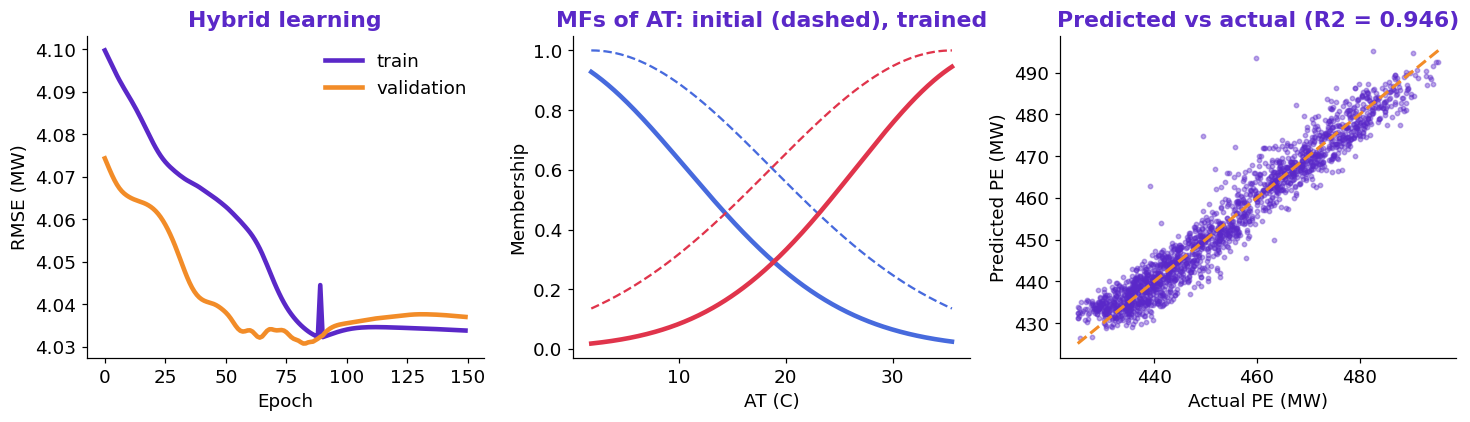

In [9]:
axis = torch.linspace(0, 1, 300)
real_axis = axis.numpy() * (x_max[0] - x_min[0]) + x_min[0]
gauss = lambda c, s: torch.exp(-((axis - c) ** 2) / (2 * s ** 2)).numpy()

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4))
ax[0].plot(history["fit"], color=PURPLE, lw=3, label="train")
ax[0].plot(history["val"], color=ORANGE, lw=3, label="validation")
ax[0].set(title="Hybrid learning", xlabel="Epoch", ylabel="RMSE (MW)")
ax[0].legend()

sigmas_now = model.log_sigmas.exp().detach()
for j, color in enumerate((BLUE, RED)):
    ax[1].plot(real_axis, gauss(initial_centers[0, j], initial_sigmas[0, j]), "--", color=color, lw=1.5)
    ax[1].plot(real_axis, gauss(model.centers[0, j].detach(), sigmas_now[0, j]), color=color, lw=3)
ax[1].set(title="MFs of AT: initial (dashed), trained", xlabel="AT (C)", ylabel="Membership")

ax[2].scatter(test.PE, y_pred, s=8, alpha=0.4, color=PURPLE)
limits = [test.PE.min(), test.PE.max()]
ax[2].plot(limits, limits, "--", color=ORANGE, lw=2)
ax[2].set(title=f"Predicted vs actual (R2 = {r2:.3f})", xlabel="Actual PE (MW)", ylabel="Predicted PE (MW)")
fig.tight_layout()
plt.show()

In [10]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "03_anfis.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "ANFIS",
    "dataset": "Combined Cycle Power Plant (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"RMSE (MW)": round(rmse, 2), "MAE (MW)": round(mae, 2), "R2": round(r2, 4), "Linear RMSE (MW)": round(rmse_linear, 2), "Rules": model.n_rules, "Parameters": n_premise + n_consequent, "Train time (s)": round(train_seconds)},
}
(results_dir / "03_anfis.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "ANFIS",
  "dataset": "Combined Cycle Power Plant (UCI)",
  "n_samples": 9568,
  "metrics": {
    "RMSE (MW)": 3.96,
    "MAE (MW)": 3.06,
    "R2": 0.9461,
    "Linear RMSE (MW)": 4.5,
    "Rules": 16,
    "Parameters": 96,
    "Train time (s)": 32
  }
}


## What to remember
- ANFIS keeps the structure of fuzzy rules, but the numbers come from data.
- Least squares does most of the work, which is why training converges in few epochs.
- With three membership functions per input, the rule count would be 3^4 = 81. That is the curse of dimensionality again.